# Simulação

Compare N = 32, 64, 128 e 256 para uma senoide de 5 ciclos por registro. Os tempos são medianas de cinco execuções e dependem da máquina.

Execute as células em ordem. Os dados são sintéticos; não representam medições experimentais.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import pandas as pd
from IPython.display import display
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True})

def espectro(x, fs, janela=None, nfft=None):
    w = np.ones(len(x)) if janela is None else janela
    X = np.fft.rfft(x*w, n=nfft)
    f = np.fft.rfftfreq(len(x) if nfft is None else nfft, 1/fs)
    A = np.abs(X)/w.sum()
    A[1:] *= 2
    if (len(x) if nfft is None else nfft) % 2 == 0:
        A[-1] /= 2
    return f, A

def plano(b, a, ax):
    # Coeficientes em potências de z^-1; completar graus para exibir polos na origem.
    grau = max(len(b), len(a))-1
    z = np.roots(np.pad(b, (0, grau+1-len(b))))
    p = np.roots(np.pad(a, (0, grau+1-len(a))))
    theta = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(theta), np.sin(theta), 'k--', label='Círculo unitário')
    ax.scatter(z.real, z.imag, facecolors='none', edgecolors='C0', label='Zeros')
    ax.scatter(p.real, p.imag, marker='x', color='C1', label='Polos')
    ax.set(xlabel='Parte real', ylabel='Parte imaginária', title='Plano z')
    ax.axis('equal'); ax.legend()

def analisar(b, a=(1,), fs=1000, nome='Filtro'):
    w, H = signal.freqz(b, a, worN=4096, fs=fs)
    impulso = np.r_[1., np.zeros(119)]
    h = signal.lfilter(b, a, impulso)
    fig, ax = plt.subplots(2, 3, figsize=(14, 7))
    ax[0,0].stem(np.arange(len(h)), h); ax[0,0].set(title=nome+' — impulso', xlabel='n (amostras)', ylabel='h[n]')
    plano(np.asarray(b), np.asarray(a), ax[0,1])
    ax[0,2].plot(w, np.abs(H)); ax[0,2].set(title='Magnitude linear', xlabel='f (Hz)', ylabel='Ganho')
    ax[1,0].plot(w, 20*np.log10(np.maximum(np.abs(H), 1e-12))); ax[1,0].set(title='Magnitude em dB', xlabel='f (Hz)', ylabel='Ganho (dB)', ylim=(-100,5))
    fase = np.unwrap(np.angle(H))
    ax[1,1].plot(w, fase); ax[1,1].set(title='Fase', xlabel='f (Hz)', ylabel='Fase (rad)')
    gd = -np.gradient(fase, 2*np.pi*w/fs)
    gd[np.abs(H)<1e-5] = np.nan
    ax[1,2].plot(w, gd); ax[1,2].set(title='Atraso de grupo (fora dos nulos)', xlabel='f (Hz)', ylabel='Amostras')
    fig.tight_layout(); plt.show()
    print('b =', np.asarray(b)); print('a =', np.asarray(a))
    print('Polos:', np.roots(a), 'Estável causal:', np.all(np.abs(np.roots(a)) < 1))


,N,DFT (s),FFT (s),Erro máximo
0,32,0.000267,0.000007,1.139129e-13
1,64,0.000604,0.000008,2.993740e-13
2,128,0.001531,0.000009,1.346403e-12
3,256,0.004367,0.000010,4.066505e-12


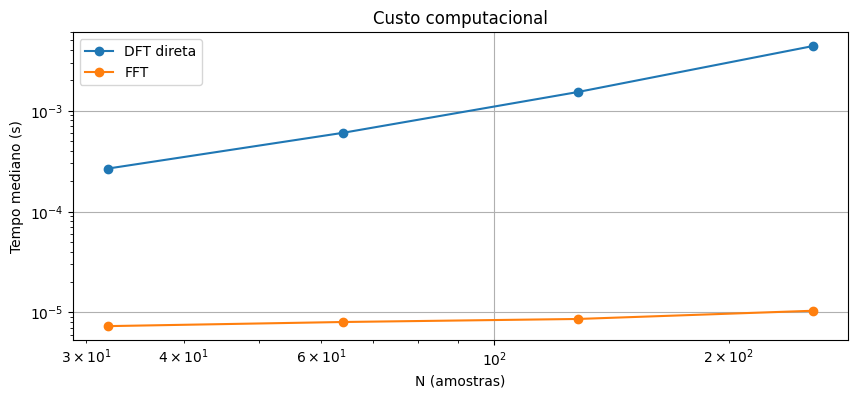

In [2]:
from time import perf_counter
linhas=[]
for N in [32,64,128,256]:
    n=np.arange(N); x=np.cos(2*np.pi*5*n/N)
    def direta(x):
        return np.array([np.sum(x*np.exp(-2j*np.pi*k*n/N)) for k in range(N)])
    tempos=[]
    for metodo in [direta,np.fft.fft]:
        medicoes=[]
        for _ in range(5):
            inicio=perf_counter(); X=metodo(x); medicoes.append(perf_counter()-inicio)
        tempos.append(np.median(medicoes))
    erro=np.max(np.abs(direta(x)-np.fft.fft(x)))
    assert erro < 1e-9
    linhas.append([N,*tempos,erro])
df=pd.DataFrame(linhas,columns=['N','DFT (s)','FFT (s)','Erro máximo']); display(df)
plt.loglog(df.N,df['DFT (s)'],'o-',label='DFT direta'); plt.loglog(df.N,df['FFT (s)'],'o-',label='FFT')
plt.xlabel('N (amostras)'); plt.ylabel('Tempo mediano (s)'); plt.title('Custo computacional'); plt.legend(); plt.show()